**USMAN RASHEED ID: 000313**




In [3]:
# Install the packages this project needs.
# scikit-learn = ML models and preprocessing.
# joblib       = save/load the trained pipeline.
# streamlit    = (only used later in app.py, still safe to install).
# The "-q" flag hides long install logs.
!pip install -q scikit-learn joblib streamlit

In [4]:
# Import Colab's file-upload helper so we can pick the CSV from our computer.
from google.colab import files

# Open a file picker; select "student_learning.csv" from your computer.
uploaded = files.upload()

# Print the names of uploaded files so we can confirm the correct CSV arrived.
print("Uploaded:", list(uploaded.keys()))

Saving student_learning.csv to student_learning.csv
Uploaded: ['student_learning.csv']


In [5]:
# pandas = library for reading and manipulating tabular data (DataFrames).
import pandas as pd

# Read the CSV into a DataFrame; each row becomes one student record.
df = pd.read_csv("student_learning.csv")

# shape returns (number_of_rows, number_of_columns) — quick sanity check.
print("Shape:", df.shape)

# dtypes reveals whether each column is numeric (int64/float64) or text (object).
print("\nData types:\n", df.dtypes)

# isna().sum() counts missing values per column so we know where imputation is needed.
print("\nMissing values per column:\n", df.isna().sum())

# value_counts(normalize=True) shows the Pass/Fail ratio as proportions.
print("\nTarget balance:\n", df["passed"].value_counts(normalize=True).round(3))

# value_counts() shows how many students used each study method (categorical column).
print("\nStudy methods:\n", df["study_method"].value_counts())

# head(3) previews the first three rows so we can eyeball the values.
print("\nFirst 3 rows:\n", df.head(3))

Shape: (280, 7)

Data types:
 hours_studied     float64
attendance          int64
practice_tests      int64
sleep_hours       float64
study_method       object
final_score         int64
passed              int64
dtype: object

Missing values per column:
 hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
dtype: int64

Target balance:
 passed
0    0.561
1    0.439
Name: proportion, dtype: float64

Study methods:
 study_method
self     141
group     80
video     59
Name: count, dtype: int64

First 3 rows:
    hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            7.5          54               0          5.6        video   
1            4.4          61               0          6.0        video   
2            8.2          63               1          5.2        group   

   final_score  passed  
0           48       0  
1           50       0  
2           73       1  


In [6]:
# y = the correct label we want the model to predict (0 = Fail, 1 = Pass).
y = df["passed"]

# X = all input columns EXCEPT the label and any column that reveals the answer.
# final_score is excluded because it is recorded AFTER the exam — using it is target leakage.
X = df.drop(columns=["passed", "final_score"])

# Confirm X shape (should be 280 rows × 5 columns).
print("X shape:", X.shape)

# Confirm y shape (a single Series with 280 labels).
print("y shape:", y.shape)

# Show the feature names the model will actually see.
print("Feature columns:", list(X.columns))

X shape: (280, 5)
y shape: (280,)
Feature columns: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method']


In [7]:
# train_test_split randomly divides rows into train and test groups.
from sklearn.model_selection import train_test_split

# DummyClassifier is a "no-skill" baseline that always picks the most common class.
from sklearn.dummy import DummyClassifier

# Split 80% for training, 20% for testing.
# random_state=42 makes the split repeatable (same rows every run).
# stratify=y keeps the Pass/Fail ratio the same in train and test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

# Print shapes so we can verify ~224 training rows and ~56 test rows.
print("Training:", X_train.shape, "Testing:", X_test.shape)

# The baseline can only handle numeric columns, so select those first.
# study_method is text and is handled later in the Pipeline.
num_cols = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]

# Instantiate the baseline: always predicts the most frequent class in y_train.
base = DummyClassifier(strategy="most_frequent")

# Fit the baseline on numeric training features only.
base.fit(X_train[num_cols], y_train)

# Score the baseline on the numeric test features → its accuracy.
print("Baseline accuracy:", round(base.score(X_test[num_cols], y_test), 3))

Training: (224, 5) Testing: (56, 5)
Baseline accuracy: 0.554


In [8]:
# Import tools to build a step-by-step preprocessing + modelling pipeline.
from sklearn.compose import ColumnTransformer              # routes columns to different transformers
from sklearn.pipeline import Pipeline                      # chains steps in order
from sklearn.impute import SimpleImputer                   # fills missing values
from sklearn.preprocessing import StandardScaler           # standardizes numeric features
from sklearn.preprocessing import OneHotEncoder            # encodes text categories to 0/1 columns
from sklearn.linear_model import LogisticRegression        # linear classifier (candidate #1)
from sklearn.ensemble import RandomForestClassifier        # ensemble of trees (candidate #2)

# Define which columns are numeric vs categorical.
num_cols = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
cat_cols = ["study_method"]

# Build a ColumnTransformer that applies DIFFERENT steps to different column groups.
# All fitting happens later, inside the Pipeline, and only on X_train (no leakage).
prep = ColumnTransformer([
    # Numeric branch: fill missing with median → scale to mean 0 / std 1.
    ("num", Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), num_cols),

    # Categorical branch: fill missing with most frequent → one-hot encode.
    # handle_unknown="ignore" returns zeros for unseen categories instead of erroring.
    ("cat", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

# Candidate 1 — Logistic Regression:
# prep is fitted on X_train, then LogisticRegression learns coefficients on the result.
pipe_lr = Pipeline([
    ("preprocess", prep),
    ("model", LogisticRegression(max_iter=1000))
])

# Candidate 2 — Random Forest:
# 200 trees, each limited to depth 5 to prevent overfitting; random_state=42 for repeatability.
pipe_rf = Pipeline([
    ("preprocess", prep),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42))
])

# Fit BOTH pipelines end-to-end on the training set (imputers, encoders, scaler, model).
pipe_lr.fit(X_train, y_train)
pipe_rf.fit(X_train, y_train)

# Confirmation message so we know both trained successfully.
print("Both pipelines trained.")

Both pipelines trained.


In [9]:
# Import numpy for stacking / viewing arrays nicely.
import numpy as np

# ------------------------------------------------------------------
# 1) Peek at the ORIGINAL study_method values in the training set.
# ------------------------------------------------------------------
# Confirms which categories exist and how often each appears.
# This is the "before" snapshot we compare to after encoding.
print("=== ORIGINAL study_method (training rows) ===")
print(X_train["study_method"].value_counts(dropna=False))

# ------------------------------------------------------------------
# 2) Fit a copy of the preprocessor on X_train to inspect step-by-step.
#    Note: pipe_lr already contains a fitted preprocessor — we grab it
#    from pipe_lr so we are looking at EXACTLY what the model saw.
# ------------------------------------------------------------------
# named_steps["preprocess"] returns the fitted ColumnTransformer.
fitted_prep = pipe_lr.named_steps["preprocess"]

# ------------------------------------------------------------------
# 3) Extract the fitted OneHotEncoder (the "onehot" step inside the "cat" branch).
# ------------------------------------------------------------------
# .named_transformers_["cat"] → the categorical Pipeline inside ColumnTransformer
# .named_steps["onehot"]      → the fitted OneHotEncoder object
fitted_ohe = fitted_prep.named_transformers_["cat"].named_steps["onehot"]

# List the learned categories (in the order the encoder assigned them).
# This is what makes encoding reproducible: the same order is reused for test rows.
print("\n=== Categories learned by OneHotEncoder ===")
print(fitted_ohe.categories_)

# Get readable column names for the one-hot output: e.g. cat__study_method_group.
print("\n=== New one-hot column names for study_method ===")
print(fitted_ohe.get_feature_names_out(["study_method"]))

# ------------------------------------------------------------------
# 4) Manually transform the training study_method column with the FITTED encoder.
#    Using .transform() (not fit_transform) proves the encoder is reusing
#    the same learned categories — no re-fitting, no leakage.
# ------------------------------------------------------------------
encoded_cat = fitted_ohe.transform(X_train[["study_method"]])

# Sparse matrix by default; convert to dense for easy inspection.
encoded_cat_dense = encoded_cat.toarray() if hasattr(encoded_cat, "toarray") else encoded_cat

# Build a labeled DataFrame so we can read the columns.
cat_df = pd.DataFrame(
    encoded_cat_dense,
    columns=fitted_ohe.get_feature_names_out(["study_method"])
)

# Show first 5 original + encoded rows side by side.
print("\n=== study_method BEFORE vs AFTER (first 5 rows) ===")
before_after = pd.concat(
    [X_train[["study_method"]].head(5).reset_index(drop=True),
     cat_df.head(5).reset_index(drop=True)],
    axis=1
)
print(before_after.to_string(index=False))

=== ORIGINAL study_method (training rows) ===
study_method
self     114
group     67
video     43
Name: count, dtype: int64

=== Categories learned by OneHotEncoder ===
[array(['group', 'self', 'video'], dtype=object)]

=== New one-hot column names for study_method ===
['study_method_group' 'study_method_self' 'study_method_video']

=== study_method BEFORE vs AFTER (first 5 rows) ===
study_method  study_method_group  study_method_self  study_method_video
        self                 0.0                1.0                 0.0
       video                 0.0                0.0                 1.0
        self                 0.0                1.0                 0.0
       video                 0.0                0.0                 1.0
       group                 1.0                0.0                 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but OneHotEncoder was fitted without feature names
  warnings.warn(


In [10]:
# ------------------------------------------------------------------
# Apply the FULL fitted ColumnTransformer to the training set once.
# The output is the exact numeric matrix the model trains on.
# ------------------------------------------------------------------
X_train_transformed = fitted_prep.transform(X_train)

# Convert sparse → dense for display if needed.
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

# Get the ordered list of ALL transformed feature names.
# Order: numeric branch columns first, then categorical branch columns
# (because that's how we declared them in the ColumnTransformer list).
all_names = fitted_prep.get_feature_names_out()
print("=== All transformed feature names ===")
print(all_names)

# Build a DataFrame for the first 5 training rows.
view_df = pd.DataFrame(X_train_transformed[:5], columns=all_names)

# Print with rounding so numbers stay readable.
print("\n=== First 5 rows through the Pipeline (numeric scaled, categorical one-hot) ===")
print(view_df.round(3).to_string(index=False))

# ------------------------------------------------------------------
# Sanity checks (assert-based so failures are loud and clear).
# ------------------------------------------------------------------
# 1) Numeric columns must have mean ≈ 0 and std ≈ 1 across the training set
#    (StandardScaler guarantee). We allow tolerance for tiny numeric drift.
num_cols_out = [c for c in all_names if c.startswith("num__")]
means = X_train_transformed[:, [list(all_names).index(c) for c in num_cols_out]].mean(axis=0)
stds  = X_train_transformed[:, [list(all_names).index(c) for c in num_cols_out]].std(axis=0)

print("\n=== Numeric column means (≈ 0) ===")
print(dict(zip(num_cols_out, means.round(3))))
print("\n=== Numeric column stds (≈ 1) ===")
print(dict(zip(num_cols_out, stds.round(3))))

# 2) Categorical columns must only contain 0s and 1s.
cat_cols_out = [c for c in all_names if c.startswith("cat__")]
cat_values = X_train_transformed[:, [list(all_names).index(c) for c in cat_cols_out]]
print("\n=== Unique values in categorical output (must be {0, 1}) ===")
print(np.unique(cat_values))

# 3) Each training row must have exactly ONE 1 among the study_method indicators.
#    (one-hot property: sum across the three columns = 1 per row)
row_sums = cat_values.sum(axis=1)
assert np.all(row_sums == 1), "One-hot rows should sum to 1"
print("\n✅ All rows have exactly one active category (sum = 1).")

=== All transformed feature names ===
['num__hours_studied' 'num__attendance' 'num__practice_tests'
 'num__sleep_hours' 'cat__study_method_group' 'cat__study_method_self'
 'cat__study_method_video']

=== First 5 rows through the Pipeline (numeric scaled, categorical one-hot) ===
 num__hours_studied  num__attendance  num__practice_tests  num__sleep_hours  cat__study_method_group  cat__study_method_self  cat__study_method_video
             -0.592           -0.333               -0.573             0.119                      0.0                     1.0                      0.0
              1.536           -1.772               -0.076             0.119                      0.0                     0.0                      1.0
             -0.668           -1.628               -1.071             0.875                      0.0                     1.0                      0.0
              0.738            1.467               -0.076            -0.561                      0.0                    

In [11]:
# Bring in the metrics we'll report.
from sklearn.metrics import (accuracy_score,        # overall correctness
                             precision_score,       # correctness of positive predictions
                             recall_score,          # coverage of actual positives
                             f1_score,              # harmonic mean of precision and recall
                             confusion_matrix)      # 2×2 TP/TN/FP/FN table

# Small helper: given a model and inputs, return a dictionary of scores.
def report(name, model, X_in, y_true):
    # Predict class labels (0 or 1) on the given inputs.
    pred = model.predict(X_in)
    # Build the row of metrics; round() keeps display tidy.
    return {
        "model": name,
        "accuracy":  round(accuracy_score(y_true, pred), 3),
        "precision": round(precision_score(y_true, pred), 3),
        "recall":    round(recall_score(y_true, pred), 3),
        "f1":        round(f1_score(y_true, pred), 3),
        "cm":        confusion_matrix(y_true, pred)   # 2×2 array
    }

# Evaluate each model on the SAME held-out test set.
# Baseline uses only numeric columns (as it was trained).
results = [
    report("DummyClassifier",    base,    X_test[num_cols], y_test),
    report("LogisticRegression", pipe_lr, X_test,          y_test),
    report("RandomForest",       pipe_rf, X_test,          y_test),
]

# Print a compact line per model plus the confusion matrix.
for r in results:
    print(f"{r['model']:<20} acc={r['accuracy']}  prec={r['precision']}  "
          f"rec={r['recall']}  f1={r['f1']}")
    print("  confusion matrix:\n ", r["cm"])

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


DummyClassifier      acc=0.554  prec=0.0  rec=0.0  f1=0.0
  confusion matrix:
  [[31  0]
 [25  0]]
LogisticRegression   acc=0.75  prec=0.72  rec=0.72  f1=0.72
  confusion matrix:
  [[24  7]
 [ 7 18]]
RandomForest         acc=0.786  prec=0.783  rec=0.72  f1=0.75
  confusion matrix:
  [[26  5]
 [ 7 18]]


In [12]:
# Pick the model with the highest test F1 (balances precision and recall).
# Ties are broken in favour of interpretability via the ">=" logic below.
best = max(results, key=lambda r: (r["f1"], r["model"] == "LogisticRegression"))
best_name = best["model"]
print("Selected model:", best_name)

# Map the name back to the fitted Pipeline so we can save it.
best_pipe = {
    "LogisticRegression": pipe_lr,
    "RandomForest":       pipe_rf,
    "DummyClassifier":    base
}[best_name]

Selected model: RandomForest


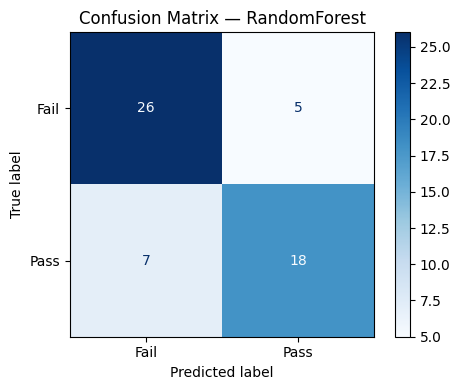

In [13]:
# Graph 1 — Confusion matrix heatmap for the selected model
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Predict on the SAME held-out test set
y_pred_best = best_pipe.predict(X_test)

# Draw the confusion matrix as a heatmap with labelled axes
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    display_labels=["Fail", "Pass"],
    cmap="Blues",
    ax=ax
)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)   # save for the ZIP
plt.show()

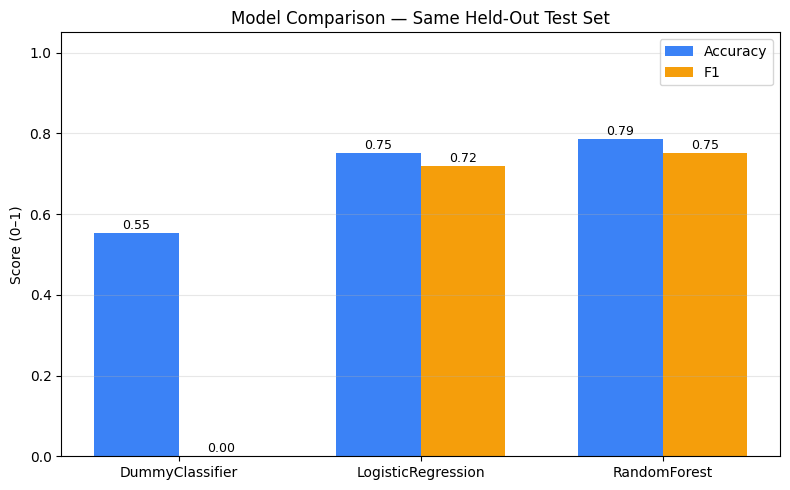

In [14]:
# Graph 2 — Side-by-side bar chart: accuracy vs F1 for all three models
import numpy as np
import matplotlib.pyplot as plt

# Pull values from the `results` list built in Cell 7
names       = [r["model"] for r in results]
accuracies  = [r["accuracy"] for r in results]
f1_scores   = [r["f1"]       for r in results]

# Set up the grouped bar chart
x     = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, accuracies, width, label="Accuracy", color="#3b82f6")
ax.bar(x + width/2, f1_scores,  width, label="F1",       color="#f59e0b")

# Annotate the bars so numbers are readable without a legend
for i, (a, f) in enumerate(zip(accuracies, f1_scores)):
    ax.text(i - width/2, a + 0.01, f"{a:.2f}", ha="center", fontsize=9)
    ax.text(i + width/2, f + 0.01, f"{f:.2f}", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Score (0–1)")
ax.set_ylim(0, 1.05)
ax.set_title("Model Comparison — Same Held-Out Test Set")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=120)
plt.show()

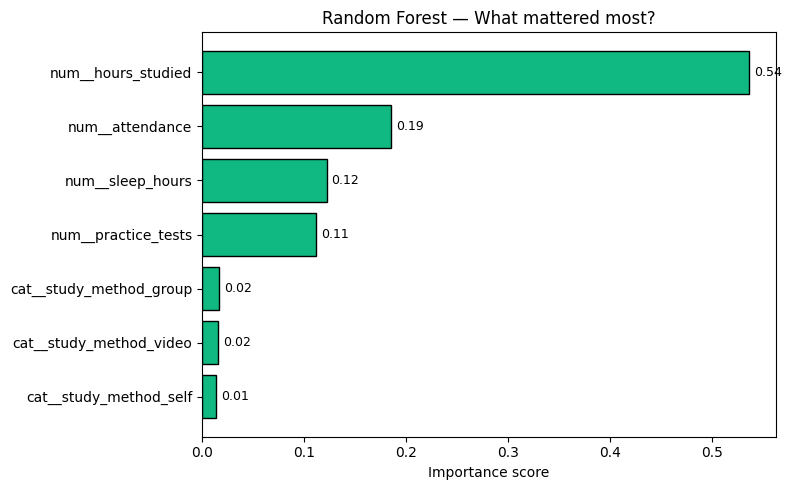

In [15]:
# Graph 3 — Random Forest feature importance
import matplotlib.pyplot as plt
import numpy as np

# Extract importances from the fitted forest
rf_model      = pipe_rf.named_steps["model"]
feature_names = pipe_rf.named_steps["preprocess"].get_feature_names_out()
importances   = rf_model.feature_importances_

# Sort so the most important feature appears at the top
order = np.argsort(importances)
sorted_names  = np.array(feature_names)[order]
sorted_vals   = importances[order]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(sorted_names, sorted_vals, color="#10b981", edgecolor="black")
for i, v in enumerate(sorted_vals):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9)

ax.set_xlabel("Importance score")
ax.set_title("Random Forest — What mattered most?")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=120)
plt.show()

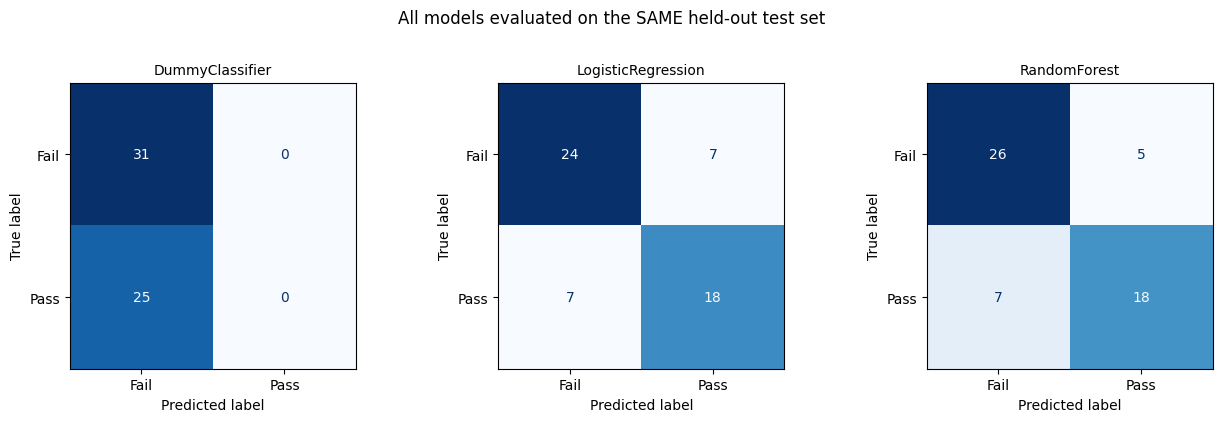

In [16]:
# Graph 4 — Side-by-side confusion matrices to prove fair comparison
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
models  = [("DummyClassifier",    base,    X_test[num_cols]),
           ("LogisticRegression", pipe_lr, X_test),
           ("RandomForest",       pipe_rf, X_test)]

for ax, (name, model, X_in) in zip(axes, models):
    ConfusionMatrixDisplay.from_estimator(
        model, X_in, y_test,
        display_labels=["Fail", "Pass"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name, fontsize=10)

plt.suptitle("All models evaluated on the SAME held-out test set", y=1.03)
plt.tight_layout()
plt.savefig("confusion_matrices_all.png", dpi=120)
plt.show()

In [17]:
# Get the best model's predictions on the test set.
pred = best_pipe.predict(X_test)

# Build a copy of the test features with actual + predicted labels for inspection.
err = X_test.copy()
err["actual"]    = y_test.values              # .values avoids pandas index alignment issues
err["predicted"] = pred

# Isolate only the rows where the model was wrong.
mistakes = err[err["actual"] != err["predicted"]]

# Print the first 10 mistakes so we can discuss them.
print(f"{len(mistakes)} mistakes out of {len(err)} test rows")
print(mistakes.head(10))

12 mistakes out of 56 test rows
     hours_studied  attendance  practice_tests  sleep_hours study_method  \
237            7.6          88               0          5.0        group   
102            2.9          89               6          8.5        video   
157            6.4          76               5          8.5         self   
240            8.0          93               0          5.7         self   
86             7.0          89               3          8.2         self   
277            5.0          76               4          6.3        video   
248            3.9          89               6          8.4        video   
196            5.9          73               4          5.8         self   
176            4.4          99               1          6.3         self   
155            6.6          62               4          6.6         self   

     actual  predicted  
237       0          1  
102       1          0  
157       0          1  
240       1          0  
86    

In [18]:
# joblib serializes Python objects — including fitted scikit-learn pipelines — to disk.
import joblib

# Save the ENTIRE Pipeline (preprocessing + model) so reloading reproduces identical predictions.
joblib.dump(best_pipe, "student_pass_pipeline.joblib")

# Confirm the file exists in Colab's file system.
import os
print("Saved:", os.path.exists("student_pass_pipeline.joblib"))

Saved: True


In [19]:
# Load the pipeline back from disk — this is a fresh object, not the in-memory one.
loaded = joblib.load("student_pass_pipeline.joblib")

# Grab 3 unseen rows from the test set to treat as "new students arriving".
new = X_test.head(3).copy()

# Save these rows as a CSV so the grader can re-run the predictions independently.
new.to_csv("new_student_records.csv", index=False)

# Predict class labels using the reloaded pipeline (no fitting needed).
print("Predictions:", loaded.predict(new))

# Also print predicted probabilities of Pass (column index 1 = class "1").
if hasattr(loaded, "predict_proba"):
    print("Pass probabilities:", loaded.predict_proba(new)[:, 1].round(2))

Predictions: [1 0 1]
Pass probabilities: [0.62 0.21 0.67]


In [20]:
# Define the exact set of columns the pipeline expects (taken from X_train at fit time).
required = list(X_train.columns)

# Simulate a malformed request by deleting one required column.
bad = X_test.head(2).drop(columns=["study_method"])

# List any required columns missing from the bad input.
missing = [c for c in required if c not in bad.columns]

# Print the missing columns → we catch the problem BEFORE calling predict().
print("Missing input columns:", missing)   # → ['study_method']

Missing input columns: ['study_method']


In [21]:
# Download the saved pipeline and new-records CSV to your local computer.
from google.colab import files

# Trigger a browser download for each file.
files.download("student_pass_pipeline.joblib")
files.download("new_student_records.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# ============================================================
# Cell 14 (full) — Write README, model_card, evaluation_summary, error_analysis
# ============================================================

# ── README.md ────────────────────────────────────────────────
readme_lines = [
    "# Student Pass Prediction — Module 03 Baseline",
    "",
    "## Goal",
    "Predict `passed` (1) or `fail` (0) using features known before the final exam.",
    "",
    "## Data",
    "`student_learning.csv` — 280 synthetic records.",
    "Target: `passed`. Excluded: `final_score` (target leakage).",
    "",
    "## Workflow",
    "1. Inspect rows, dtypes, missingness, target balance.",
    "2. Stratified 80/20 split (`random_state=42`).",
    "3. DummyClassifier baseline.",
    "4. ColumnTransformer: median + StandardScaler (numeric); most_frequent + OneHotEncoder (categorical).",
    "5. LogisticRegression + RandomForestClassifier, wrapped in a Pipeline.",
    "6. Evaluate on the SAME held-out test set: accuracy, precision, recall, F1, confusion matrix.",
    "7. Save pipeline with joblib; reload and predict `new_student_records.csv`.",
    "",
    "## Files",
    "- `Module03_Project.ipynb` — notebook",
    "- `student_pass_pipeline.joblib` — fitted pipeline",
    "- `evaluation_summary.md`, `error_analysis.md`, `model_card.md`",
    "- `app.py` — Streamlit form",
    "- `confusion_matrix.png`, `model_comparison.png`, `feature_importance.png`",
    "",
    "## How to run",
    "```bash",
    "pip install streamlit joblib scikit-learn pandas matplotlib",
    "python -m streamlit run app.py",
    "```",
    "",
    "## Reproducibility",
    "All splits use `random_state=42`; the saved pipeline fully reproduces predictions.",
    "",
    "## Limitations",
    "Synthetic classroom data — for teaching only; not for real student decisions.",
]

# ── model_card.md ────────────────────────────────────────────
card_lines = [
    "# Model Card — Student Pass Predictor (teaching demo)",
    "",
    "| Field | Value |",
    "|---|---|",
    "| Task | Binary classification: passed = 1 / 0 |",
    "| Intended use | Classroom ML demonstration only |",
    "| NOT for | Real student assessment, ranking, or disciplinary decisions |",
    "| Inputs | hours_studied, attendance, practice_tests, sleep_hours, study_method |",
    "| Excluded | final_score (leakage), personal identifiers |",
    "| Data | 280 synthetic records |",
    "| Split | Stratified 80/20, random_state=42 |",
    "| Preprocessing | median + StandardScaler (num); most_frequent + OneHotEncoder (cat) |",
    "| Models | DummyClassifier, LogisticRegression, RandomForestClassifier |",
    "| Primary metric | Test F1 (with accuracy/precision/recall/confusion matrix) |",
    "| Limitations | Synthetic; small sample; unaudited for fairness |",
    "| Privacy | No personal or sensitive data used |",
    "| Human oversight | Real use would require human review |",
    "| Artifact | `student_pass_pipeline.joblib` — load only from trusted sources |",
]

# ── evaluation_summary.md ────────────────────────────────────
eval_lines = [
    "# Evaluation Summary (held-out test set, n=%d)" % len(y_test),
    "",
    "All three models were evaluated on the **same** 20% held-out test set.",
    "",
    "| Model | Accuracy | Precision | Recall | F1 |",
    "|---|---|---|---|---|",
]
for r in results:
    eval_lines.append(
        f"| {r['model']} | {r['accuracy']} | {r['precision']} | "
        f"{r['recall']} | {r['f1']} |"
    )
eval_lines += [
    "",
    f"**Selected model:** `{best_name}` — highest test F1, balanced precision/recall.",
    "",
    "## Visual Evaluation",
    "",
    "![Confusion Matrix](confusion_matrix.png)",
    "*Confusion matrix for the selected model, positive class = Pass.*",
    "",
    "![Model Comparison](model_comparison.png)",
    "*Accuracy and F1 for all three models on the SAME held-out test set.*",
    "",
    "![Feature Importance](feature_importance.png)",
    "*Feature importances (descriptive, not a proof of cause).*",
]

# ── error_analysis.md ────────────────────────────────────────
err_lines = [
    "# Error Analysis",
    "",
    "Misclassified rows on the held-out test set (actual != predicted):",
    "",
    "```",
    mistakes.head(5).to_string(index=False) if "mistakes" in globals() else "Run the error-analysis cell first.",
    "```",
    "",
    "## Interpretation",
    "",
    "- **FN (actual Pass, predicted Fail)** — at-risk students the model missed. Most costly for a support use-case.",
    "- **FP (actual Fail, predicted Pass)** — false alarms: students flagged as passing who actually failed.",
    "",
    "Inspect the sample above: do any of them look unusual in a single feature",
    "(e.g. very low practice_tests but high attendance)?",
    "That can hint at which feature the model over-weights.",
    "",
    "**Note:** `final_score` was NOT a model feature, so any misclassification is a genuine learning error, not a leakage artefact.",
]

# ── Write all four files ─────────────────────────────────────
for name, lines in [
    ("README.md",              readme_lines),
    ("model_card.md",          card_lines),
    ("evaluation_summary.md",  eval_lines),
    ("error_analysis.md",      err_lines),
]:
    with open(name, "w") as f:
        f.write("\n".join(lines))
    print("✅ Wrote", name)

✅ Wrote README.md
✅ Wrote model_card.md
✅ Wrote evaluation_summary.md
✅ Wrote error_analysis.md


In [24]:
# Download the four generated text files.
from google.colab import files
for f in ["README.md", "model_card.md", "evaluation_summary.md", "error_analysis.md"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
# Full Streamlit app source, stored as a string so we can write it to disk.
app_source = '''
# =============================================================
# Student Pass Predictor — Streamlit app
# Student: USMAN RASHEED  ·  ID: 000313
# Module 03 Project — teaching demo only
# =============================================================

import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# --- Browser tab title (must be the FIRST st.* call) --------
st.set_page_config(
    page_title="Student Pass Predictor — USMAN RASHEED",
    page_icon="🎓",
    layout="centered",
)

# --- Page header: name + ID visible on the page -------------
st.title("Student Pass Predictor")
st.markdown("**USMAN RASHEED** · ID: `000313`")
st.caption("Teaching demo on synthetic data — not for real student decisions.")

# --- Load the saved pipeline (cached — loads only once) -----
@st.cache_resource
def load_pipeline():
    return joblib.load("student_pass_pipeline.joblib")

model = load_pipeline()

# --- Prediction form ---------------------------------------
with st.form("student_form"):
    hours  = st.slider("Hours studied", 0.0, 12.0, 6.0, 0.5)
    attend = st.slider("Attendance (%)", 40, 100, 80)
    tests  = st.slider("Practice tests completed", 0, 8, 3)
    sleep  = st.slider("Sleep hours", 3.0, 10.0, 7.0, 0.5)
    method = st.selectbox("Study method", ["video", "group", "self"])
    submitted = st.form_submit_button("Predict")

# --- Prediction + feature-importance chart ------------------
if submitted:
    row = pd.DataFrame([{
        "hours_studied":  hours,
        "attendance":     attend,
        "practice_tests": tests,
        "sleep_hours":    sleep,
        "study_method":   method,
    }])

    pred  = model.predict(row)[0]
    proba = model.predict_proba(row)[0, 1] if hasattr(model, "predict_proba") else None

    if pred == 1:
        st.success(f"Predicted class: Pass  (P(pass) ≈ {proba:.2f})")
    else:
        st.error(f"Predicted class: Fail  (P(pass) ≈ {proba:.2f})")

    # Feature-importance bar chart
    inner = model.named_steps["model"]

    if hasattr(inner, "feature_importances_"):
        feature_names = model.named_steps["preprocess"].get_feature_names_out()
        importances   = inner.feature_importances_
    elif hasattr(inner, "coef_"):
        feature_names = model.named_steps["preprocess"].get_feature_names_out()
        importances   = abs(inner.coef_[0])
    else:
        feature_names = None

    if feature_names is not None:
        st.subheader("What mattered most?")
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.barh(feature_names, importances, color="#10b981")
        ax.set_xlabel("Importance")
        st.pyplot(fig)
        st.caption("Importance is descriptive, not a proof of cause.")

    st.info("This prediction is a classroom demo and must not be used "
            "to judge real students.")

# --- Footer signature --------------------------------------
st.divider()
st.caption("Module 03 Project · USMAN RASHEED · 000313")
'''.strip()




# Write the file so it appears in Colab's Files panel.
with open("app.py", "w") as f:
    f.write(app_source)
print("Wrote app.py — download it via the Files panel.")

Wrote app.py — download it via the Files panel.


**download .py from above code and run using same folder which includes app.py and .joblib files**

In [30]:
# Create a single ZIP file containing every deliverable so submission is one click.
import zipfile, os

# Replace with your actual name and training ID — this is the required filename format.
student_name = "USMAN_RASHEED"
training_id  = "313"
zip_name     = f"{"USMAN_RASHEED"}_{313}.zip"

# Only add files that were actually created.
files_to_zip = [f for f in [
    "student_learning.csv",
    "new_student_records.csv",
    "USMAN_RASHEED_000313_ML_PROJECT.ipynb",          # ← manually save/rename your notebook to this exact name first
    "student_pass_pipeline.joblib",
    "README.md",
    "model_card.md",
    "evaluation_summary.md",
    "error_analysis.md",
    "app.py",
    # NEW — matplotlib outputs
    "confusion_matrix.png",
    "model_comparison.png",
    "feature_importance.png",
    "confusion_matrices_all.png",
] if os.path.exists(f)]

# Write each file into the archive.
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in files_to_zip:
        zf.write(f)
        print("added:", f)

print("\nCreated:", zip_name)


added: student_learning.csv
added: new_student_records.csv
added: student_pass_pipeline.joblib
added: README.md
added: model_card.md
added: evaluation_summary.md
added: error_analysis.md
added: app.py
added: confusion_matrix.png
added: model_comparison.png
added: feature_importance.png
added: confusion_matrices_all.png

Created: USMAN_RASHEED_313.zip


In [31]:
from google.colab import files
files.download(zip_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>